In [19]:
## Python Stuff
import os
import sys
import numpy as np
from array import array
import copy
import time
import matplotlib.pyplot as plt
import matplotlib
import json5 as json

import uproot

os.environ.get("ROOTSYS")

'/Users/austindestcroix/packages/root_py311_v6_26.10/myInstall_p311'

In [20]:
## ROOT stuff
import ROOT
from ROOT import TFile, TTree, TCanvas
from ROOT import TH1F, TH2F
import ctypes
import copy

ROOT.gStyle.SetCanvasDefW(600)
ROOT.gStyle.SetCanvasDefH(500)

# ROOT.gErrorIgnoreLevel = ROOT.kFatal
ROOT.gROOT.SetBatch(False)
# ROOT.enableJSVis()
# ROOT.disableJSVis()

## Atown's stuff
sys.path.append("..")
from globalsC2 import *
from helpers.anaStructs import * # includes SORTING class/namespace
from helpers.getSPE import *
import helpers.graphBuilders as GB

import MakeSpectra as MS

In [21]:
runs, voltages = np.loadtxt(os.path.join(COMP2PATH, "runLists", "bkg_voltage_runs.txt"), unpack=True, delimiter = ",", dtype=int, skiprows=1)

pathAnaJson = "../pyScripts/speAnalysis.json"
pathFileJson = "../pyScripts/files.json"

runs, speValues, rcObjList, tFiles = MS.ExtractSPE(fileConfig=pathFileJson, anaConfig=pathAnaJson, argRunList=runs)

anaCfg = MS.AnalysisConfig(json.load(open(pathAnaJson, 'r')))
for rc, v in zip(rcObjList, voltages):
  rc.mVoltage = v
  # rc.setup_forComparison_np()
  rc.print()
  
  rc.UprootConstructor()

{'dataRoot': '/procData/analysis1/', 'runDir': 'runLists/', 'runList': 'bkg_voltage_runs.txt', 'filePattern': 'npv1_{}.root', 'treeName': 'tt'}
getting runs: [202204141206 202204141158 202204141138 202204141143 202204141147
 202204141151 202204141154]

runID: 202204141206
Nevents: 11213.00,   time: 8.54 min
average Rate: 21.88 Hz
chID:0: spe = 78.78 +/- 0.31     maxChi2 = 19.72
chID:1: spe = 85.43 +/- 0.54     maxChi2 = 20.98
chID:2: spe = 85.44 +/- 0.47     maxChi2 = 35.46

runID: 202204141158
Nevents: 10163.00,   time: 5.27 min
average Rate: 32.14 Hz
chID:0: spe = 115.76 +/- 0.42     maxChi2 = 10.62
chID:1: spe = 121.53 +/- 0.69     maxChi2 = 39.22
chID:2: spe = 121.05 +/- 0.54     maxChi2 = 3.05

runID: 202204141138
Nevents: 10089.00,   time: 4.58 min
average Rate: 36.69 Hz
chID:0: spe = 150.14 +/- 0.46     maxChi2 = 6.82
chID:1: spe = 156.96 +/- 0.77     maxChi2 = 19.65
chID:2: spe = 157.84 +/- 0.63     maxChi2 = 1.96

runID: 202204141143
Nevents: 10190.00,   time: 3.95 min
average

---
### Finger plots and rates

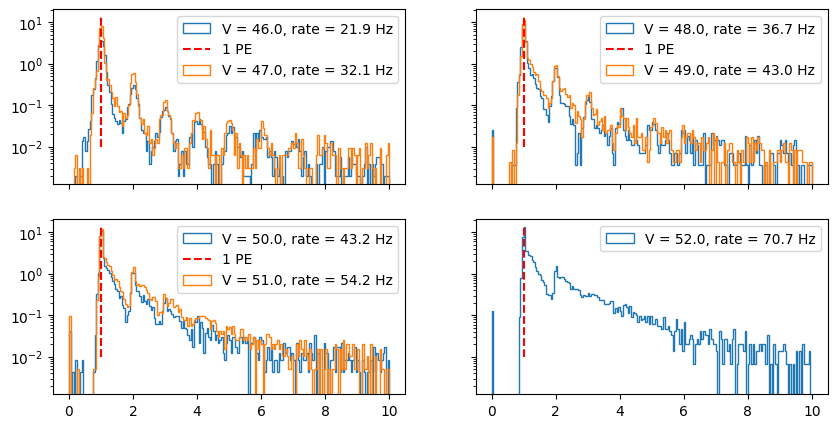

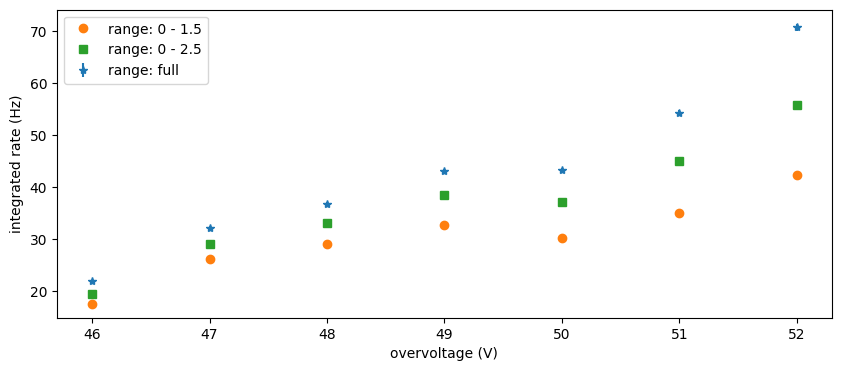

In [22]:
fig, axes = plt.subplots(2, 2, figsize = (10, 5), sharex = True, sharey=True)
axes = axes.flatten()
for rc in rcObjList:
  ax = axes[int(rcObjList.index(rc)//2)]
    
  rc.setup_forComparison_np(Nbins = 200, lowRange=0, maxRange=10, qvar = anaCfg.qvar)
  
  rc.mpl_hist(ax, True, histtype = "step", label = f"V = {rc.mVoltage:0.1f}, rate = {rc.GetRate():0.1f} Hz")
  ax.set_yscale("log")
  ax.legend()
  
  ax.vlines(x=1.0, ymin=0.01, ymax=15, color='r', linestyle='--', label='1 PE')
  
def TestRCsum(rc):
  total = np.sum(rc.mBin_rate)
  return total

fig, axes = plt.subplots(1, 1, figsize =(10, 4))
rates = np.array([rc.GetRate() for rc in rcObjList])
ratesError = [rc.GetRateError() for rc in rcObjList]
axes.errorbar(voltages, rates, yerr = ratesError, marker = "*", linestyle = "None", label = "range: full")

ratesLow = [rc.GetNP_integral(0, 1.5) for rc in rcObjList]
axes.plot(voltages, ratesLow, marker = "o", linestyle = "None", label = "range: 0 - 1.5")

ratesMid = [rc.GetNP_integral(0, 2.5) for rc in rcObjList]
axes.plot(voltages, ratesMid, marker = "s", linestyle = "None", label = "range: 0 - 2.5")

axes.set_xlabel("overvoltage (V)")
axes.set_ylabel("integrated rate (Hz)")

plt.legend()
plt.show()

---
### SPE values and chi2

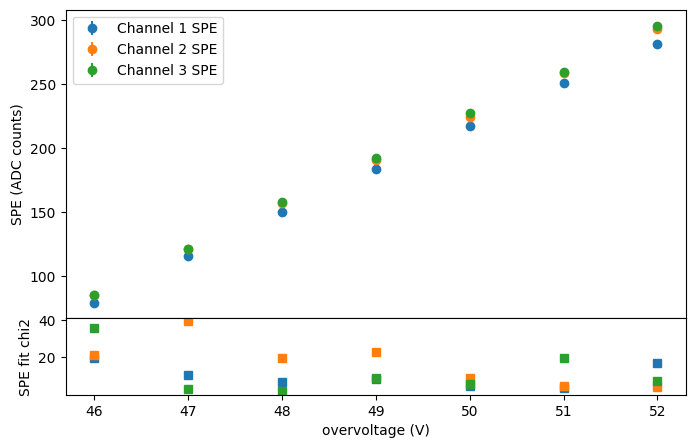

In [23]:
speFig, (speAx, axchi2) = plt.subplots(2, 1, figsize =(8, 5), height_ratios = [4, 1], sharex=True)
plt.subplots_adjust(hspace=0)

## not including horizontal uncertainty in voltage
for ichan in range(anaCfg.nChan):
  spe = np.array([rc.GetChan(ichan).mSpe.spe for rc in rcObjList])
  spe_err = np.array([rc.GetChan(ichan).mSpe.espe for rc in rcObjList])
  spe_chi2 = np.array([rc.GetChan(ichan).mSpe.chi2 for rc in rcObjList])

# plot channel 1 SPE vs voltage
  speAx.errorbar(voltages, spe, yerr = spe_err, marker = "o", linestyle = "None", label = f"Channel {ichan+1} SPE")
  axchi2.plot(voltages, spe_chi2, marker = "s", linestyle = "None", label = f"Channel {ichan+1} SPE chi2")
  
speAx.set_xlabel("overvoltage (V)")
speAx.set_ylabel("SPE (ADC counts)")

axchi2.set_xlabel("overvoltage (V)")
axchi2.set_ylabel("SPE fit chi2")
speAx.legend(loc = 'upper left')
plt.show()

---
### Fitting for breakdown

Single line fit: <ValueView m=34.8466464210604 b=43.62875329008194>
Three-line fit (shared slope): <ValueView m=34.678729935352216 b0=43.706978557170345 b1=43.516087793162775 b2=43.491999498201146>


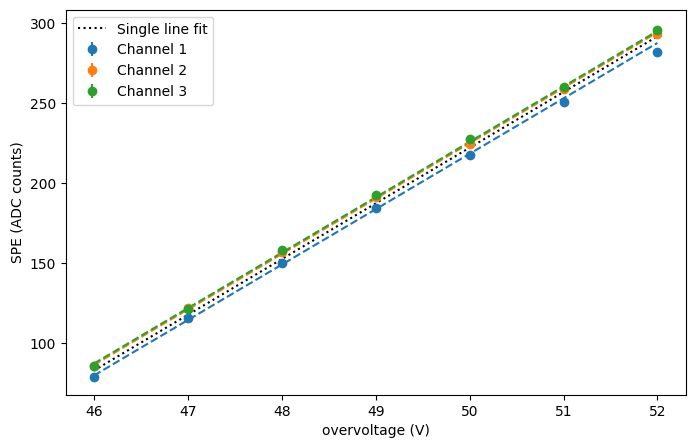

Breakdown voltage avg: 43.629 +/- 0.010


In [29]:
# Simple fits to SPE vs voltage using iminuit
import iminuit
from iminuit import Minuit

# Gather data
voltages = np.array([rc.mVoltage for rc in rcObjList])
nChan = anaCfg.nChan
spe_all = np.concatenate([np.array([rc.GetChan(i).mSpe.spe for rc in rcObjList]) for i in range(nChan)])
spe_err_all = np.concatenate([np.array([rc.GetChan(i).mSpe.espe for rc in rcObjList]) for i in range(nChan)])
volts_all = np.tile(voltages, nChan)
chan_idx = np.concatenate([np.full(len(voltages), i) for i in range(nChan)])

# 1. Fit a single line to all data
def line(x, m, b):
    return m*(x-b)

def chi2_line(m, b):
    return np.sum(((spe_all - line(volts_all, m, b)) / spe_err_all) ** 2)

m1 = Minuit(chi2_line, m=100, b=40)
m1.migrad()
print("Single line fit:", m1.values)
# print(m1)

# 2. Fit three lines (shared slope, separate intercepts)
def multi_line(x, chan, m, b0, b1, b2):
    b = np.choose(chan, [b0, b1, b2])
    return m*(x - b)

def chi2_multi(m, b0, b1, b2):
    return np.sum(((spe_all - multi_line(volts_all, chan_idx, m, b0, b1, b2)) / spe_err_all) ** 2)

m2 = Minuit(chi2_multi, m=100, b0=40, b1=40, b2=40)
m2.migrad()
print("Three-line fit (shared slope):", m2.values)

# Plot results
fig, ax = plt.subplots(figsize=(8,5))
colors = ['C0', 'C1', 'C2']
for i in range(nChan):
    spe = np.array([rc.GetChan(i).mSpe.spe for rc in rcObjList])
    spe_err = np.array([rc.GetChan(i).mSpe.espe for rc in rcObjList])
    ax.errorbar(voltages, spe, yerr=spe_err, marker='o', linestyle='None', color=colors[i], label=f'Channel {i+1}')
    # Plot fit for each channel
    fit_y = m2.values['m'] * (voltages - m2.values[f'b{i}'])
    ax.plot(voltages, fit_y, color=colors[i], linestyle='--')
    
# Plot single line fit
ax.plot(voltages, m1.values['m'] * (voltages - m1.values['b']), color='k', linestyle=':', label='Single line fit')
ax.set_xlabel('overvoltage (V)')
ax.set_ylabel('SPE (ADC counts)')
ax.legend()
plt.show()

print(f"Breakdown voltage avg: {m1.values['b']:0.3f} +/- {m1.errors['b']:0.3f}")

vbr = m1.values['b']

---
### Looking at NCAs

In [30]:
## load giacomo's data
datV, datCA = np.loadtxt(COMP2PATH+ "/literatureData/giacomoNoise_newVUV4.txt", delimiter=",", skiprows=1, unpack = True)
datV2, datCA2 = np.loadtxt(COMP2PATH+ "/literatureData/giacomoNoise_oldVUV4.txt", delimiter=",", skiprows=1, unpack = True)

46 NCA =  1.91 0.4 0.22
47 NCA =  1.6 0.37 0.22
48 NCA =  1.39 0.4 0.26
49 NCA =  1.5 0.46 0.32
50 NCA =  1.6 0.58 0.43
51 NCA =  1.69 0.68 0.54
52 NCA =  1.73 0.83 0.66


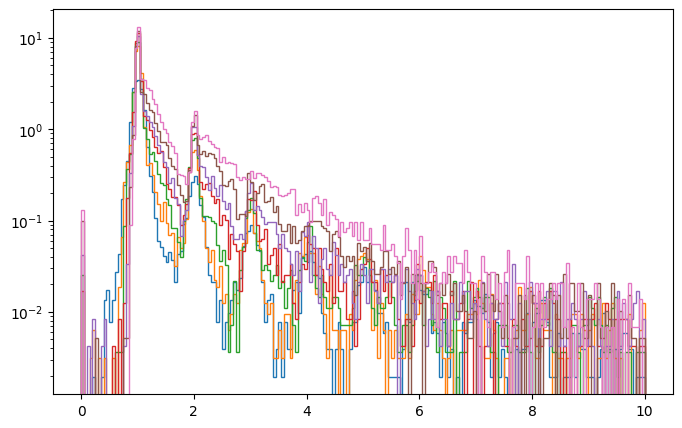

In [65]:
fig, ax = plt.subplots(figsize=(8,5))

ncaMean = []
ncaMeanRestricted = []
ncaHistMean = []
histBounds = (0.5, 5.0)

for rc in rcObjList:
  ## print rc members
  speVals = rc.GetSPEArray(qvar=anaCfg.qvar)
  
  rc.setup_forComparison_np(Nbins = 200, lowRange=0, maxRange=10, qvar = anaCfg.qvar)
  binCenters = 0.5*(rc.mBin_edges[1:] + rc.mBin_edges[:-1])
  histMean = np.sum(binCenters * rc.mBin_rawCounts) / np.sum(rc.mBin_rawCounts)
  
  ncaMean.append(np.mean(speVals)-1.0)
  ncaHistMean.append(histMean-1.0)
  
  restrictedMean = np.mean(speVals[(speVals > histBounds[0]) & (speVals < histBounds[1])])
  ncaMeanRestricted.append(restrictedMean-1.0)
  
  print(rc.mVoltage, "NCA = ", round(np.mean(speVals)-1.0, 2), round(histMean-1.0, 2), round(restrictedMean-1.0,2))
  
  rc.mpl_hist(ax, True, histtype = "step", label = f"V = {rc.mVoltage:0.1f} V")
ax.set_yscale("log")

NCA fraction at 48V (new VUV4):  0.15828604141472172


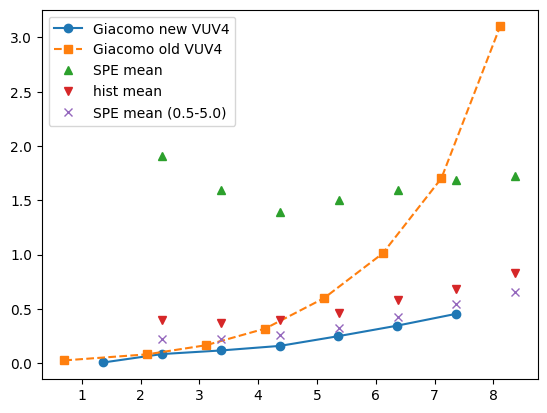

In [66]:
plt.plot(datV, datCA, marker='o', linestyle='-', label='Giacomo new VUV4')
plt.plot(datV2, datCA2, marker='s', linestyle='--', label='Giacomo old VUV4')

plt.plot(voltages-vbr, ncaMean, marker='^', linestyle='None', label='SPE mean')
plt.plot(voltages-vbr, ncaHistMean, marker='v', linestyle='None', label='hist mean')
plt.plot(voltages-vbr, ncaMeanRestricted, marker='x', linestyle='None', label=f'SPE mean ({histBounds[0]}-{histBounds[1]})')

plt.legend()

import scipy.interpolate as spInterpolate
fCA = spInterpolate.interp1d(datV, datCA, kind = "cubic")
print("NCA fraction at 48V (new VUV4): ", fCA(48.0-vbr))